# Engenharia de Atributos e Pré-Processamento (Feature Engineering)

**Projeto:** Data Science & Machine Learning Practice  
**Módulo:** 02 - Feature Engineering & Encoding  
**Dataset Base:** Flight Price Cleaned (`data/processed/flight_price_cleaned.csv`)  

---

## Objetivo Deste Notebook
O objetivo desta etapa é realizar todo o trabalho de **Engenharia de Atributos (Feature Engineering), Tratamento Categórico (Encoding) e Escalonamento (Scaling)** preparando o conjunto de dados para treinamento de modelos de Machine Learning (como Regressão Linear, Ridge, Lasso, Elastic Net e algoritmos baseados em árvores), abordando:
- Criação de **funções modulares e reutilizáveis** para transformações de dados (evitando repetição de código).
- Extração de variáveis temporais analíticas a partir de horários de partida e chegada.
- Identificação de voos que cruzam a meia-noite (chegada no dia seguinte).
- Mapeamento e tratamento de variáveis ordinais (`Total_Stops`).
- Codificação de variáveis categóricas nominais (`One-Hot Encoding` vs `Target Encoding`), considerando a armadilha das variáveis dummy (*Dummy Variable Trap*) e multicolinearidade.
- Tratamento de categorias raras e baixa representatividade amostral (ex: *Trujet*).
- Construção de pipelines reprodutíveis via `ColumnTransformer` do scikit-learn, evitando vazamento de dados (*Data Leakage*).
- Avaliação de transformações na variável alvo (`Price`) para atenuar a assimetria positiva à direita.

---

## Abordagem Crítica vs. Aula Tradicional

| Aspecto | Abordagem da Aula (Professor) | Minha Abordagem (Boas Práticas de ML) |
| :--- | :--- | :--- |
| **Modularidade do Código** | Código procedural repetitivo: fez splits e conversões manuais para cada coluna, copiando e colando blocos idênticos. | **Metodologia Modular (DRY - *Don't Repeat Yourself*)**: criei funções genéricas e reutilizáveis para horários, categorias e mapeamentos. |
| **Prevenção de Data Leakage** | Aplicou `OneHotEncoder` no dataset inteiro sem divisão prévia. | Separação estrita de Treino e Teste (`train_test_split`) **antes** de ajustar encoders e scalers (`fit` no treino, `transform` no teste). |
| **Horários de Partida e Chegada** | Apenas quebrou em hora/minuto e dropou os originais. | Criei períodos do dia (*Morning*, *Afternoon*, *Night*) e sinalizador de chegada no dia seguinte (*Arrival_Next_Day*). |
| **Variáveis Ordinais (`Total_Stops`)** | Mapeamento manual com imputação arbitrária de nulos. | Mapeamento numérico ordinal fundamentado, preservando a hierarquia natural ($0 < 1 < 2 < 3 < 4$). |
| **Tratamento de Categorias Raras** | Deixou categorias com 1 ou 3 voos gerarem colunas dummy isoladas. | Tratamento de baixa frequência via função de consolidação de classes raras. |
| **Estrutura de Código** | Vários passos soltos e dataframes temporários desconectados. | Pipeline profissional com `ColumnTransformer` e `Pipeline` do scikit-learn. |


## 1. Setup e Importação de Bibliotecas


In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import warnings

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from IPython.display import display

warnings.filterwarnings('ignore')

# Configurações visuais
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 5)
plt.rcParams['font.size'] = 11


## 2. Carregamento da Base Limpa da EDA

Carrego o arquivo resultante da etapa anterior em `data/processed/flight_price_cleaned.csv`.


In [43]:
file_paths = [
    '../../data/processed/flight_price_cleaned.csv',
    'data/processed/flight_price_cleaned.csv',
    'flight_price_cleaned.csv'
]

data_path = None
for path in file_paths:
    if os.path.exists(path):
        data_path = path
        break

if data_path is None:
    raise FileNotFoundError("Base limpa 'flight_price_cleaned.csv' nao encontrada.")

print(f"Carregando dados limpos de: {data_path}")
df = pd.read_csv(data_path)
print(f"Shape: {df.shape[0]} linhas e {df.shape[1]} colunas.")
df.head(3)


Carregando dados limpos de: ../../data/processed/flight_price_cleaned.csv
Shape: 10462 linhas e 18 colunas.


,Airline,Date_of_Journey,Source,Destination,Route,Dep_Time,Arrival_Time,Duration,Total_Stops,Additional_Info,Price,Journey_Date,Journey_Day,Journey_Month,Journey_Month_Name,Journey_Day_of_Week,Is_Weekend,Duration_Minutes
0,IndiGo,24/03/2019,Banglore,Delhi,BLR → DEL,22:20,01:10 22 Mar,2h 50m,non-stop,No info,3897,2019-03-24,24,3,March,Sunday,1,170
1,Air India,1/05/2019,Kolkata,Banglore,CCU → IXR → BBI → BLR,05:50,13:15,7h 25m,2 stops,No info,7662,2019-05-01,1,5,May,Wednesday,0,445
2,Jet Airways,9/06/2019,Delhi,Cochin,DEL → LKO → BOM → COK,09:25,04:25 10 Jun,19h,2 stops,No info,13882,2019-06-09,9,6,June,Sunday,1,1140


## 3. Metodologia Modular: Criação de Funções Reutilizáveis

> ### Nota Crítica: Modularidade vs. Código Procedural Repetitivo
> Na aula do curso, o professor executou cada operação de forma manual e repetitiva: escreveu um bloco inteiro de código com splits, conversões de tipo e drops para `Dep_Time`, e depois copiou e colou praticamente o mesmo bloco para `Arrival_Time`, além de comandos manuais individuais para cada categoria.  
> Essa abordagem viola o princípio fundamental do desenvolvimento de software: **DRY (*Don't Repeat Yourself*)**. Código repetido é propenso a erros de digitação e difícil de manter.  
> 
> Aqui adotei uma metodologia modular: criei funções parametrizadas para cada responsabilidade, tornando o fluxo limpo, reutilizável e escalável para novos datasets.


In [44]:
def extract_time_features(dataframe, col_name, prefix):
    """
    Extrai componentes de horario (hora, minuto, periodo do dia e 
    indicador de chegada no dia seguinte) de uma coluna de horario.
    
    Parametros:
    -----------
    dataframe : pd.DataFrame
        DataFrame contendo a coluna a ser processada.
    col_name : str
        Nome da coluna de horario original (ex: 'Dep_Time' ou 'Arrival_Time').
    prefix : str
        Prefixo a ser atribuido as novas features geradas (ex: 'Dep' ou 'Arrival').
        
    Retorno:
    --------
    pd.DataFrame:
        Copia do DataFrame com as novas colunas temporais adicionadas.
    """
    data = dataframe.copy()
    
    # 1. Isola o horario base (remove indicacao de data caso exista em Arrival_Time)
    time_series = data[col_name].astype(str).apply(lambda x: x.split(' ')[0])
    
    # 2. Extrai hora e minuto como inteiros
    data[f'{prefix}_Hour'] = time_series.apply(lambda x: int(x.split(':')[0]))
    data[f'{prefix}_Minute'] = time_series.apply(lambda x: int(x.split(':')[1]))
    
    # 3. Detecta se ha chegada no dia seguinte (presenca de data no Arrival_Time)
    if 'Arrival' in prefix:
        data[f'{prefix}_Is_Next_Day'] = data[col_name].astype(str).str.contains(' ').astype(int)
        
    # 4. Classifica em periodos do dia de forma padronizada
    def classify_period(hour):
        if 0 <= hour < 6:
            return 'Early_Morning'
        elif 6 <= hour < 12:
            return 'Morning'
        elif 12 <= hour < 18:
            return 'Afternoon'
        else:
            return 'Evening_Night'
            
    data[f'{prefix}_Period'] = data[f'{prefix}_Hour'].apply(classify_period)
    return data


def consolidate_rare_categories(dataframe, col_name, min_freq=20, custom_label=None):
    """
    Agrupa categorias com frequencia inferior a min_freq sob um rotulo consolidado,
    evitando a criacao de colunas dummy quase vazias e falhas no teste.
    
    Parametros:
    -----------
    dataframe : pd.DataFrame
        DataFrame contendo a coluna categorica.
    col_name : str
        Nome da coluna a ser tratada.
    min_freq : int
        Frequencia minima para a categoria ser mantida individualmente (padrao: 20).
    custom_label : str, opcional
        Nome da categoria agregadora (se None, sera 'Other_<col_name>').
        
    Retorno:
    --------
    pd.DataFrame:
        DataFrame com a nova coluna categorica limpa (sufixo '_Clean').
    """
    data = dataframe.copy()
    counts = data[col_name].value_counts()
    rare_categories = counts[counts < min_freq].index.tolist()
    
    label = custom_label if custom_label else f'Other_{col_name}'
    data[f'{col_name}_Clean'] = data[col_name].apply(lambda x: label if x in rare_categories else x)
    return data


def encode_ordinal_feature(dataframe, col_name, mapping_dict):
    """
    Mapeia uma variavel categorica ordinal para numeros inteiros
    preservando a hierarquia natural do atributo.
    """
    data = dataframe.copy()
    data[f'{col_name}_Encoded'] = data[col_name].map(mapping_dict)
    return data


## 4. Aplicação das Funções Modulares no Dataset

Com as funções estruturadas, aplico as transformações de horários e períodos em `Dep_Time` e `Arrival_Time` chamando a mesma função parametrizada:


In [45]:
# Aplicacao da funcao modular de horarios para Partida e Chegada
df = extract_time_features(df, col_name='Dep_Time', prefix='Dep')
df = extract_time_features(df, col_name='Arrival_Time', prefix='Arrival')

df[['Dep_Time', 'Dep_Hour', 'Dep_Minute', 'Dep_Period', 'Arrival_Time', 'Arrival_Hour', 'Arrival_Minute', 'Arrival_Is_Next_Day']].head()


,Dep_Time,Dep_Hour,Dep_Minute,Dep_Period,Arrival_Time,Arrival_Hour,Arrival_Minute,Arrival_Is_Next_Day
0,22:20,22,20,Evening_Night,01:10 22 Mar,1,10,1
1,05:50,5,50,Early_Morning,13:15,13,15,0
2,09:25,9,25,Morning,04:25 10 Jun,4,25,1
3,18:05,18,5,Evening_Night,23:30,23,30,0
4,16:50,16,50,Afternoon,21:35,21,35,0


### 4.1 Validação Estatística do Período de Partida

Abaixo verifico se o período de partida gerado pela função modular discrimina preços reais:


Resumo de Preco por Periodo de Partida:


,count,median,mean
Dep_Period,,,
Evening_Night,2629,8452.0,8905.075694
Afternoon,2563,8372.0,9176.259462
Morning,4224,8266.0,9093.728930
Early_Morning,1046,7351.5,8696.149140


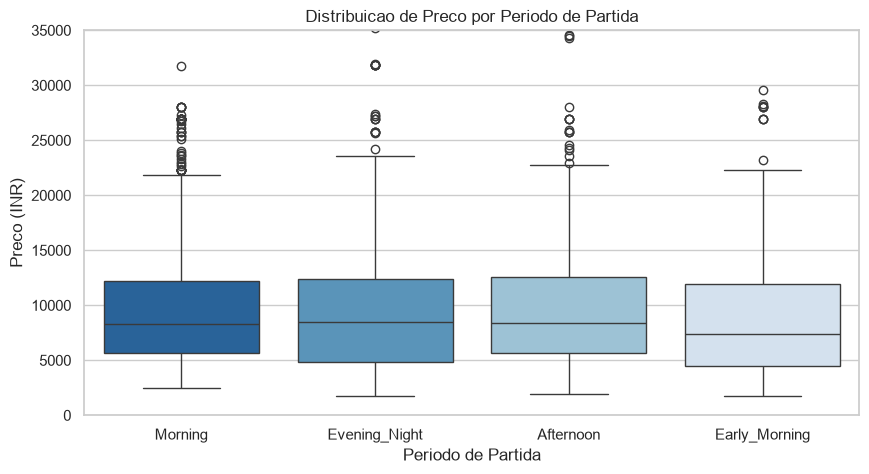

In [46]:
period_summary = df.groupby('Dep_Period')['Price'].agg(['count', 'median', 'mean']).sort_values(by='median', ascending=False)
print("Resumo de Preco por Periodo de Partida:")
display(period_summary)

plt.figure(figsize=(10, 5))
sns.boxplot(data=df, x='Dep_Period', y='Price', order=['Morning', 'Evening_Night', 'Afternoon', 'Early_Morning'], palette='Blues_r')
plt.title("Distribuicao de Preco por Periodo de Partida")
plt.xlabel("Periodo de Partida")
plt.ylabel("Preco (INR)")
plt.ylim(0, 35000)
plt.show()


## 5. Análise e Seleção de Atributos: `Route` e `Additional_Info`

### 5.1 Descarte Fundamentado de `Route`
A coluna `Route` detalha cada ponto de escala do voo.  
Como os aeroportos de partida e chegada já estão presentes em `Source` e `Destination`, e a quantidade de escalas intermediárias já está representada em `Total_Stops`, manter `Route` apenas adicionaria centenas de categorias redundantes e multicolineares. Por essa razão, descarto `Route` de forma analítica e fundamentada.


In [47]:
print(f"Total de rotas distintas em Route: {df['Route'].nunique()}")
df[['Source', 'Destination', 'Total_Stops', 'Route']].head(3)


Total de rotas distintas em Route: 128


,Source,Destination,Total_Stops,Route
0,Banglore,Delhi,non-stop,BLR → DEL
1,Kolkata,Banglore,2 stops,CCU → IXR → BBI → BLR
2,Delhi,Cochin,2 stops,DEL → LKO → BOM → COK


### 5.2 Consolidação de Categorias em `Additional_Info` e `Airline`

Utilizo a função modular `consolidate_rare_categories` para agrupar as categorias com baixa contagem amostral:


In [48]:
# Consolidando categorias raras de Additional_Info
df = consolidate_rare_categories(df, col_name='Additional_Info', min_freq=20, custom_label='Other_Info')
print("Distribuicao de Additional_Info_Clean:")
print(df['Additional_Info_Clean'].value_counts())

# Consolidando companhias aereas raras (ex: Trujet com apenas 1 voo, Vistara Premium com 3 voos)
df = consolidate_rare_categories(df, col_name='Airline', min_freq=20, custom_label='Other_Airline')
print("\nDistribuicao de Airline_Clean:")
print(df['Airline_Clean'].value_counts())


Distribuicao de Additional_Info_Clean:
Additional_Info_Clean
No info                         8185
In-flight meal not included     1926
No check-in baggage included     318
Other_Info                        33
Name: count, dtype: int64

Distribuicao de Airline_Clean:
Airline_Clean
Jet Airways          3700
IndiGo               2043
Air India            1694
Multiple carriers    1196
SpiceJet              815
Vistara               478
Air Asia              319
GoAir                 194
Other_Airline          23
Name: count, dtype: int64


## 6. Codificação de Variáveis Ordinais: `Total_Stops`

A variável `Total_Stops` possui hierarquia estrita:  
`non-stop` (0) < `1 stop` (1) < `2 stops` (2) < `3 stops` (3) < `4 stops` (4).  

Aplico a função modular `encode_ordinal_feature` para realizar o mapeamento:


In [49]:
stops_mapping = {
    'non-stop': 0,
    '1 stop': 1,
    '2 stops': 2,
    '3 stops': 3,
    '4 stops': 4
}

df = encode_ordinal_feature(df, col_name='Total_Stops', mapping_dict=stops_mapping)
df[['Total_Stops', 'Total_Stops_Encoded']].drop_duplicates().sort_values(by='Total_Stops_Encoded')


,Total_Stops,Total_Stops_Encoded
0,non-stop,0
3,1 stop,1
1,2 stops,2
402,3 stops,3
9029,4 stops,4


## 7. Definição do Conjunto de Features ($X$) e Target ($y$)

> ### Nota Crítica: A Importância da Divisão ANTES do Encoding
> 
> Na aula, o professor fez:
> ```python
> encoder = OneHotEncoder()
> encoder.fit_transform(df[['Airline', 'Source', 'Destination']])
> ```
> Ele executou o fit no dataset completo, antes de qualquer divisão.  
> **Por que isso é um erro?**  
> Porque gera **Data Leakage (Vazamento de Dados)**: se houver categorias novas ou frequências no conjunto de teste, o encoder já aprendeu informações do teste durante o pré-processamento.  
> A boa prática de Machine Learning exige:
> 1. Definir $X$ e $y$.
> 2. Dividir em `X_train`, `X_test`, `y_train`, `y_test`.
> 3. Fazer `.fit()` dos encoders e scalers **estritamente em `X_train`**.
> 4. Fazer apenas `.transform()` em `X_test`.


In [50]:
# Selecao de features preditoras finais
feature_cols = [
    'Airline_Clean',
    'Source',
    'Destination',
    'Total_Stops_Encoded',
    'Dep_Hour',
    'Dep_Minute',
    'Dep_Period',
    'Arrival_Hour',
    'Arrival_Minute',
    'Arrival_Is_Next_Day',
    'Duration_Minutes',
    'Journey_Day',
    'Journey_Month',
    'Journey_Day_of_Week',
    'Is_Weekend',
    'Additional_Info_Clean'
]

target_col = 'Price'

X = df[feature_cols].copy()
y = df[target_col].copy()

print(f"Dimensoes de X: {X.shape}")
print(f"Dimensoes de y: {y.shape}")

# Divisao estrita entre Treino (80%) e Teste (20%) com semente fixada
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print(f"Amostras de Treino: {X_train.shape[0]}")
print(f"Amostras de Teste:  {X_test.shape[0]}")


Dimensoes de X: (10462, 16)
Dimensoes de y: (10462,)
Amostras de Treino: 8369
Amostras de Teste:  2093


## 8. Construção do Pipeline com `ColumnTransformer`

Para garantir reprodutibilidade, modularidade e evitar vazamento de dados, utilizo a classe `ColumnTransformer` do scikit-learn.

Separo as colunas em três grupos bem definidos:
1. **Categóricas Nominais (One-Hot Encoding):**
   - `Airline_Clean`, `Source`, `Destination`, `Dep_Period`, `Journey_Day_of_Week`, `Additional_Info_Clean`.
   - Utilizo `handle_unknown='ignore'` para garantir robustez caso alguma categoria não vista no treino surja no teste.
   - Utilizo `sparse_output=False` para gerar matrizes densas fáceis de inspecionar.
2. **Numéricas Contínuas (Feature Scaling):**
   - `Duration_Minutes`: variável contínua com ampla escala (de 75 a mais de 2.000 minutos). Aplico `StandardScaler` (média 0, desvio 1).
3. **Numéricas/Ordinais Prontas (Passthrough):**
   - `Total_Stops_Encoded`, `Dep_Hour`, `Dep_Minute`, `Arrival_Hour`, `Arrival_Minute`, `Arrival_Is_Next_Day`, `Journey_Day`, `Journey_Month`, `Is_Weekend`. Já são numéricas delimitadas.


In [51]:
categorical_nominal_cols = [
    'Airline_Clean',
    'Source',
    'Destination',
    'Dep_Period',
    'Journey_Day_of_Week',
    'Additional_Info_Clean'
]

numerical_scaling_cols = [
    'Duration_Minutes'
]

passthrough_cols = [
    'Total_Stops_Encoded',
    'Dep_Hour',
    'Dep_Minute',
    'Arrival_Hour',
    'Arrival_Minute',
    'Arrival_Is_Next_Day',
    'Journey_Day',
    'Journey_Month',
    'Is_Weekend'
]

# Construcao do pipeline de transformacao colunar
preprocessor = ColumnTransformer(
    transformers=[
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_nominal_cols),
        ('num', StandardScaler(), numerical_scaling_cols),
        ('pass', 'passthrough', passthrough_cols)
    ],
    remainder='drop'
)

# Ajuste (.fit) EXCLUSIVO no conjunto de treino
preprocessor.fit(X_train)

# Transformacao em Treino e Teste
X_train_processed = preprocessor.transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Obtendo os nomes de todas as features resultantes apos o One-Hot Encoding
feature_names = preprocessor.get_feature_names_out()

print(f"Total de features originais: {X.shape[1]}")
print(f"Total de features apos One-Hot Encoding e Processamento: {X_train_processed.shape[1]}")
print(f"Shape final do X_train: {X_train_processed.shape}")
print(f"Shape final do X_test: {X_test_processed.shape}")


Total de features originais: 16
Total de features apos One-Hot Encoding e Processamento: 44
Shape final do X_train: (8369, 44)
Shape final do X_test: (2093, 44)


In [55]:
# Convertendo os dados processados de volta para DataFrame para inspecao clara
df_X_train_processed = pd.DataFrame(X_train_processed, columns=feature_names, index=X_train.index)
df_X_test_processed = pd.DataFrame(X_test_processed, columns=feature_names, index=X_test.index)

print("Exemplo das colunas finais geradas:")
display(df_X_train_processed.head(3).T.head(25))


Exemplo das colunas finais geradas:


,6646,6248,6790
cat__Airline_Clean_Air Asia,0.0,0.0,0.0
cat__Airline_Clean_Air India,0.0,0.0,0.0
cat__Airline_Clean_GoAir,0.0,0.0,0.0
cat__Airline_Clean_IndiGo,1.0,0.0,0.0
cat__Airline_Clean_Jet Airways,0.0,1.0,0.0
cat__Airline_Clean_Multiple carriers,0.0,0.0,1.0
cat__Airline_Clean_Other_Airline,0.0,0.0,0.0
cat__Airline_Clean_SpiceJet,0.0,0.0,0.0
cat__Airline_Clean_Vistara,0.0,0.0,0.0
cat__Source_Banglore,0.0,0.0,0.0


## 9. Discussão Teórica: A Armadilha das Variáveis Dummy (*Dummy Variable Trap*)
> Em modelos lineares (como a Regressão Linear que verei a seguir no curso), incluir **todas** as colunas binárias geradas pelo One-Hot Encoding causa o fenômeno de **multicolinearidade perfeita**.  
> Por exemplo, se houver duas categorias binárias (Fim de semana: Sim/Não), a coluna `Is_Weekend_1` é perfeitamente previsível a partir de `1 - Is_Weekend_0`.  
> Isso faz a matriz $X^T X$ ficar singular (não inversível pela fórmula analítica de Mínimos Quadrados Ordinários: $\beta = (X^T X)^{-1} X^T y$).
>
> Para evitar isso em modelos lineares puros, utiliza-se `drop='first'`.  
> Já para algoritmos baseados em árvores (Random Forest, XGBoost) e modelos regularizados como **Ridge** e **Lasso**, manter todas as categorias com penalização $L_1/L_2$ funciona perfeitamente bem.


## 10. Tratamento da Variável Alvo (`Price`): Transformação Logarítmica

Como comprovei na EDA, o preço das passagens aéreas tem **forte assimetria positiva à direita (Skewness = 1.86)**, com valores estendendo-se até quase INR 80.000.  

Para algoritmos de regressão linear e métodos baseados em gradiente, uma distribuição de resíduos normalizada é uma das premissas fundamentais.  
Abaixo comparo o `Price` original com o `log1p(Price)` (logaritmo natural de $1 + \text{Preço}$):


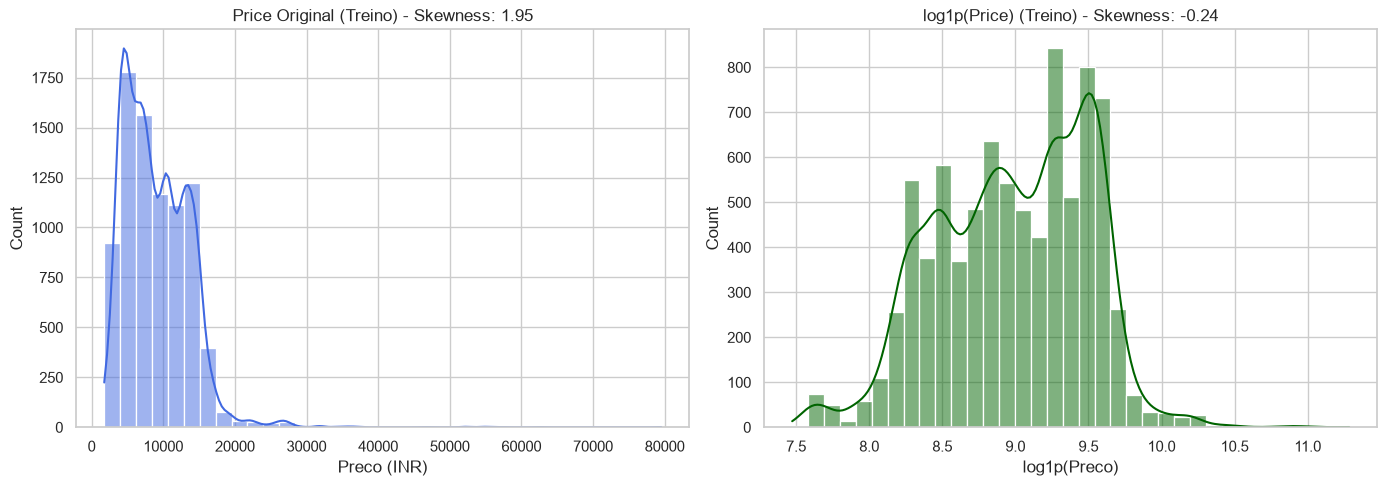

Assimetria Original: 1.95 (Forte cauda longa a direita)
Assimetria apos log1p: -0.24 (Muito mais proxima de uma distribuicao normal balanceada)


In [53]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Preco Original
sns.histplot(y_train, kde=True, color='royalblue', bins=35, ax=axes[0])
axes[0].set_title(f"Price Original (Treino) - Skewness: {y_train.skew():.2f}")
axes[0].set_xlabel("Preco (INR)")

# Preco com Transformacao Logaritmica
y_train_log = np.log1p(y_train)
y_test_log = np.log1p(y_test)

sns.histplot(y_train_log, kde=True, color='darkgreen', bins=35, ax=axes[1])
axes[1].set_title(f"log1p(Price) (Treino) - Skewness: {y_train_log.skew():.2f}")
axes[1].set_xlabel("log1p(Preco)")

plt.tight_layout()
plt.show()

print(f"Assimetria Original: {y_train.skew():.2f} (Forte cauda longa a direita)")
print(f"Assimetria apos log1p: {y_train_log.skew():.2f} (Muito mais proxima de uma distribuicao normal balanceada)")


## 11. Exportação das Bases Pré-Processadas para `data/processed/`

Para que os futuros módulos de modelagem (Regressão Linear, Regularização Ridge/Lasso, etc.) possam iniciar diretamente com os dados tratados, exporto:
- `train_preprocessed.csv` e `test_preprocessed.csv` (contendo todas as 44 features e as duas versões da variável alvo: `Target_Price` e `Target_Price_Log`).


In [54]:
output_dir = '../../data/processed' if os.path.exists('../../data/processed') else 'data/processed'

# Adicionando target aos conjuntos de treino e teste finais
train_final = df_X_train_processed.copy()
train_final['Target_Price'] = y_train.values
train_final['Target_Price_Log'] = y_train_log.values

test_final = df_X_test_processed.copy()
test_final['Target_Price'] = y_test.values
test_final['Target_Price_Log'] = y_test_log.values

train_path = os.path.join(output_dir, 'train_preprocessed.csv')
test_path = os.path.join(output_dir, 'test_preprocessed.csv')

train_final.to_csv(train_path, index=False)
test_final.to_csv(test_path, index=False)

print(f"Base de Treino salva com sucesso em: {train_path} ({train_final.shape[0]} linhas, {train_final.shape[1]} colunas)")
print(f"Base de Teste salva com sucesso em: {test_path} ({test_final.shape[0]} linhas, {test_final.shape[1]} colunas)")


Base de Treino salva com sucesso em: ../../data/processed\train_preprocessed.csv (8369 linhas, 46 colunas)
Base de Teste salva com sucesso em: ../../data/processed\test_preprocessed.csv (2093 linhas, 46 colunas)


## 12. Conclusões da Etapa de Feature Engineering

Com este pipeline estruturado e modular, concluí todas as etapas de preparação de dados para machine learning:

1. **Metodologia Modular (DRY):** Substituí código procedural repetitivo por funções parametrizadas e reutilizáveis (`extract_time_features`, `consolidate_rare_categories`, `encode_ordinal_feature`).
2. **Features Temporais Ricas:** Extraí períodos de partida (*Dep_Period*) e identifiquei chegadas noturnas no dia seguinte (*Arrival_Is_Next_Day*).
3. **Preservação de Hierarquias Ordinais:** A variável `Total_Stops` foi quantificada numericamente de 0 a 4 de forma direta e consistente.
4. **Tratamento de Categorias Raras:** Casos de baixa representatividade amostral como *Trujet* e classes executivas unitárias foram agrupados, garantindo estabilidade estatística.
5. **Sem Vazamento de Dados:** Todo o pré-processamento foi isolado via `ColumnTransformer`, com aprendizado estritamente em `X_train` e aplicação cega em `X_test`.
6. **Normalização da Variável Alvo:** Demonstrei a eficácia do `log1p(Price)` em reduzir a assimetria de +1.86 para uma distribuição muito mais simétrica, ideal para os modelos de regressão que serão desenvolvidos na sequência.
